# Using an email dataset, detect patterns of email spoofing.

In [2]:
import re
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from email.utils import parseaddr
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [4]:
df = pd.read_csv("SpamAssasin.csv")
df = df[["sender", "subject", "urls", "label"]].fillna("")
print(df.shape)
print(df["label"].value_counts())

(5809, 4)
label
0    4091
1    1718
Name: count, dtype: int64


   no_display_name  email_in_display_name  display_domain_mismatch  \
0                0                      0                        0   
1                0                      0                        0   
2                0                      0                        0   
3                0                      0                        0   
4                0                      0                        0   

   brand_name_not_in_domain  free_mail_domain  suspicious_tld  \
0                         0                 0               0   
1                         0                 0               0   
2                         0                 0               0   
3                         0                 0               0   
4                         0                 0               0   

   digits_in_address  domain_dots  invalid_sender  urgent_subject  \
0                  0            2               0               0   
1                  0            1               0 

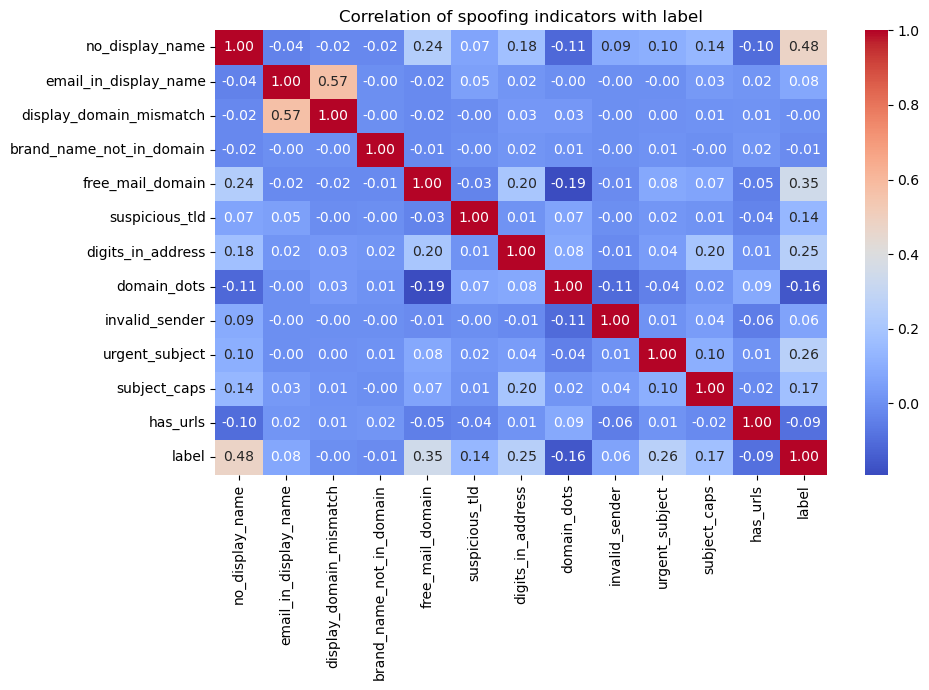

In [5]:
BRANDS = ["paypal", "amazon", "bank", "ebay", "microsoft", "apple", "google", "visa", "support", "security"]
FREE_MAIL = ["gmail.com", "yahoo.com", "hotmail.com", "aol.com", "outlook.com", "msn.com"]
BAD_TLDS = ["ru", "cn", "biz", "info", "tk", "xyz", "top"]
URGENT = ["urgent", "verify", "account", "password", "free", "winner", "click", "offer", "money", "act now"]

def get_features(row):
    name, addr = parseaddr(str(row["sender"]))
    name, addr = name.lower(), addr.lower()
    local, _, domain = addr.partition("@")
    subject = str(row["subject"]).lower()

    # email address hidden inside the display name, e.g. "service@paypal.com" <x@evil.ru>
    name_email = re.findall(r"[\w.-]+@([\w.-]+)", name)

    return pd.Series({
        "no_display_name": int(name == ""),
        "email_in_display_name": int(len(name_email) > 0),
        "display_domain_mismatch": int(len(name_email) > 0 and name_email[0] != domain),
        "brand_name_not_in_domain": int(any(b in name and b not in domain for b in BRANDS)),
        "free_mail_domain": int(domain in FREE_MAIL),
        "suspicious_tld": int(domain.split(".")[-1] in BAD_TLDS),
        "digits_in_address": sum(c.isdigit() for c in local + domain),
        "domain_dots": domain.count("."),
        "invalid_sender": int("@" not in addr),
        "urgent_subject": int(any(w in subject for w in URGENT)),
        "subject_caps": int(sum(c.isupper() for c in str(row["subject"])) > 10),
        "has_urls": int(row["urls"]),
    })

X = df.apply(get_features, axis=1)
y = df["label"]
print(X.head())

# 3. Spoofing pattern analysis
data = X.copy()
data["label"] = y
print("\nMean of each indicator (0 = legit, 1 = spam/spoofed):")
print(data.groupby("label").mean().T.round(3))

plt.figure(figsize=(10, 7))
sns.heatmap(data.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation of spoofing indicators with label")
plt.tight_layout()
plt.show()

In [6]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
}

for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    print(f"\n===== {name} =====")
    print("Accuracy:", round(accuracy_score(y_test, pred), 4))
    print(classification_report(y_test, pred, target_names=["Legitimate", "Spoofed/Spam"]))


===== Logistic Regression =====
Accuracy: 0.8133
              precision    recall  f1-score   support

  Legitimate       0.84      0.90      0.87       818
Spoofed/Spam       0.72      0.60      0.66       344

    accuracy                           0.81      1162
   macro avg       0.78      0.75      0.76      1162
weighted avg       0.81      0.81      0.81      1162


===== Decision Tree =====
Accuracy: 0.827
              precision    recall  f1-score   support

  Legitimate       0.81      0.98      0.89       818
Spoofed/Spam       0.90      0.47      0.62       344

    accuracy                           0.83      1162
   macro avg       0.85      0.72      0.75      1162
weighted avg       0.84      0.83      0.81      1162


===== Random Forest =====
Accuracy: 0.8511
              precision    recall  f1-score   support

  Legitimate       0.84      0.97      0.90       818
Spoofed/Spam       0.88      0.58      0.70       344

    accuracy                           0.85  

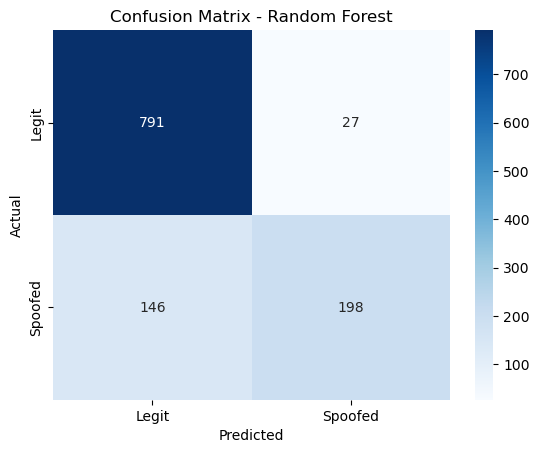

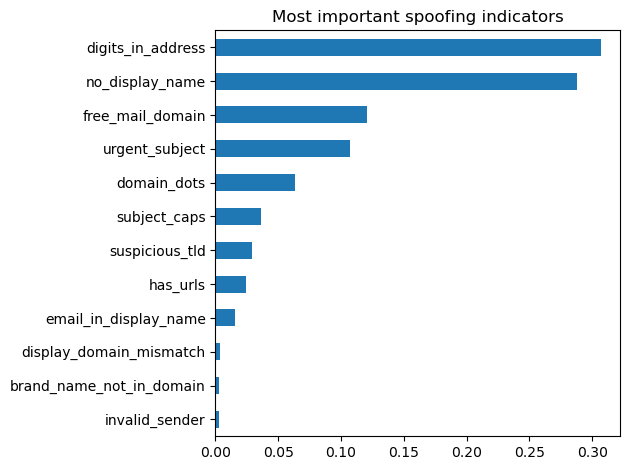

In [7]:
rf = models["Random Forest"]
sns.heatmap(confusion_matrix(y_test, rf.predict(X_test)), annot=True, fmt="d", cmap="Blues",
            xticklabels=["Legit", "Spoofed"], yticklabels=["Legit", "Spoofed"])
plt.title("Confusion Matrix - Random Forest")
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.show()

importance = pd.Series(rf.feature_importances_, index=X.columns).sort_values()
importance.plot(kind="barh", title="Most important spoofing indicators")
plt.tight_layout()
plt.show()

In [8]:
test = pd.DataFrame([{"sender": '"service@paypal.com" <alert123@secure-login.ru>',
                      "subject": "URGENT: Verify your account", "urls": 1, "label": 0}])
print("\nSample prediction:", "Spoofed" if rf.predict(test.apply(get_features, axis=1))[0] == 1 else "Legitimate")


Sample prediction: Spoofed
